<a href="https://colab.research.google.com/github/HamzaBanjanovic/fly-by-wire-simulation/blob/main/simulation/sim1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import random

a = 4 #the properties of the air causing the angular acceleration to increase, depends on air density, speed squared, wing area, the aircrafts shape, and how hard is it to rotat
b = 1 # how effective the input is, meaning how "strong" the maximum push of the pilots commands are
dt = 0.01
u = 0 # how hard the pilot pulls the stick compared to the maximum he can
theta = 0.01 # nose angle, where the plane is
omega = 0 # angular velocity aka. rotation speed, how fast the plane is turning
alpha = 0 # how hard the plane is being pushed by those forces from a, while they increase as the angle increases amplifying a
times = []
angles = []
u_values = []

'''
new position = old position + speed × little time slice
new speed = old speed + acceleration × little time slice

'''

target = 0 # where we want our nose to be, depending if stable or at a target
I = 0
e_prev = target - theta # initial error, if its
Kp = 10
Ki = 0
Kd = 3

queue = [0]*25 # delay, initial is all zeroes before the list gets filled up



In [35]:
for i in range(5000):
  # Sensors with a little noise
  s1 = theta + random.gauss(0, 0.005) # Sensor 1
  s2 = theta + random.gauss(0, 0.005) # Sensor 2
  s3 = theta + random.gauss(0, 0.005) # Sensor 3
  sensors = sorted([s1, s2, s3])

  e = target - theta # Negative if going up, signalling that the P part needs to go DOWN when influencing u (Kp*e)
  I = I + e*dt # little errors, adding them up over time
  D = (e - e_prev)/dt  # basically omega, just negative, telling us the direction the plane should to to get counterbalanced
  u = Kp*e + Ki*I + Kd*D # full controller input
  if(u < -1): # Capping the controllers push, the plane cannot physically push more than that
    u = -1
  elif(u > 1):
    u = 1


  e_prev = e


  queue.append(u) # add the current u, it will get its turn in len(queue) turns
  u_used = queue.pop(0) # remove the first element and use it as computer input, meaning its behind len(queue) * 0.01 seconds



  alpha = a * theta + b * u_used # theta times a, acceleration increases ever so slightly
  omega = omega + alpha * dt # speed of rotation infleunced by the push meaning alpha
  theta = theta + omega * dt # current angle influenced by the sum of all previous speeds
  times.append(i * dt) # add the time axis little second by little second
  angles.append(theta) # add how the angle changes over time
  u_values.append(u_used) # add the current stick push

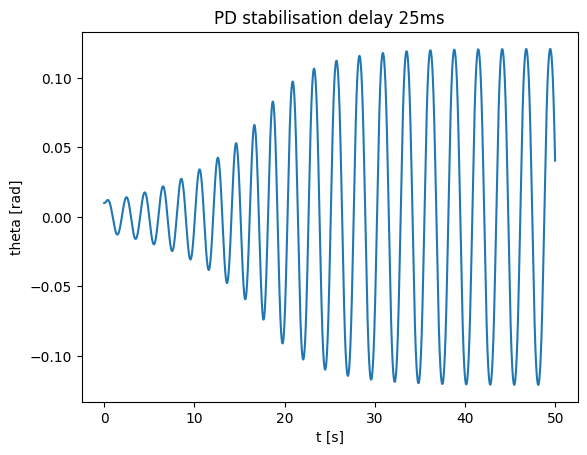

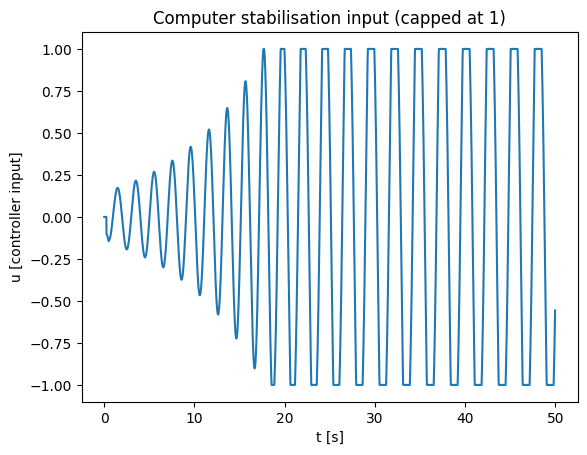

In [36]:
# Graphing the change of the angle over time using matmatplotlib
import matplotlib.pyplot as plt
plt.plot(times, angles)
plt.xlabel("t [s]")
plt.ylabel("theta [rad]")
plt.title("PD stabilisation delay 25ms")
plt.savefig("figure1.png", dpi=150)
plt.show()

plt.plot(times, u_values)
plt.xlabel("t [s]")
plt.ylabel("u [controller input]")
plt.title("Computer stabilisation input (capped at 1)")
plt.savefig("figure2.png", dpi=150)
plt.show()